In [1]:
import sys
import os
import pandas as pd

sys.path.append(os.path.abspath('..'))

from quinex_application.postprocessing.data_loading import load_property_data
from quinex_application.postprocessing.data_processing import filter_corpus, describe_corpus
from quinex_application.visualisation.metadata_visualisation import VisualisationMetadata
from quinex_application.visualisation.text_availability_visualisation import TextAvailabilityVisualisation
from quinex_application.visualisation.plot_utils import show_figure, add_corpus_note

# "all": full text and abstract-only publications, "full_text": full-text publications only
CORPUS = "all"

PAPER_PATH = "../data/paper/paper_dataset.parquet"
METADATA_PATH = "../data/quinex/df_quinex_metadata.parquet"
TECHNOLOGIES_NAN_PATH = "../data/visualisation_files/df_technologies_nan.parquet"

**Corpus:** set `CORPUS` in the first cell to `"all"` (full text and abstract-only publications) or `"full_text"` (full-text publications only, e.g. for the supplementary repetition of the analyses). Every figure states the corpus and the number of contributing publications below the plot, and saved figures get the suffix `_{CORPUS}`.

In [2]:
metadata = VisualisationMetadata(METADATA_PATH)

# **Load Data**

In [3]:
# Processed corpus: Download_Status "Succeeded" (full text) / "Abstract Succeeded" (abstract only),
# incl. publications without extracted records (Quinex == False)
df_paper = pd.read_parquet(PAPER_PATH, columns=["DOI", "Year", "Quinex", "Download_Status"])

In [4]:
metadata_df = pd.read_parquet(METADATA_PATH)

# All records, but only the columns used below (the full file needs ~7.5 GB RAM)
records_all = load_property_data(
    TECHNOLOGIES_NAN_PATH,
    properties=None,
    columns=["DOI", "Source", "Publication Year", "Entity Mapping", "Entity Base Mapping", "Property Base Mapping", "Property Mapping", "Associated Countries"],
)

# Records of the selected corpus for the principal analyses
quinex_df = filter_corpus(records_all, CORPUS)
print(describe_corpus(CORPUS, df=quinex_df))

Corpus: All publications (full text and abstract only); n = 57,523 publications (full text: 31,636, abstract only: 25,887)


In [7]:
quinex_df.columns

Index(['DOI', 'source', 'publication_year', 'entity_mapping',
       'entity_base_mapping', 'property_base_mapping', 'property_mapping',
       'associated_countries'],
      dtype='object')

In [9]:
quinex_df["property_mapping"].value_counts()

property_mapping
Cost                          109098
Efficiency                     80023
Installed Capacity             47203
CO2 emission                   36505
Number of Scenarios            34006
Levelized Cost                 31611
Capital Cost                   18442
Lifetime                       18303
Emission                       13299
GHG emission                   12906
Number of Nodes                 9427
Height                          8757
Coefficient of Performance      5611
Capacity Factor                 5542
Number of Time Steps            2193
Technology Readiness Level      1174
Name: count, dtype: int64

# **Analysis Metadata**

### **Ent & Prop Distribution**

c:\Gorres\Projekte\quinex_application\quinex_application\visualisation\metadata_visualisation.py:1073: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


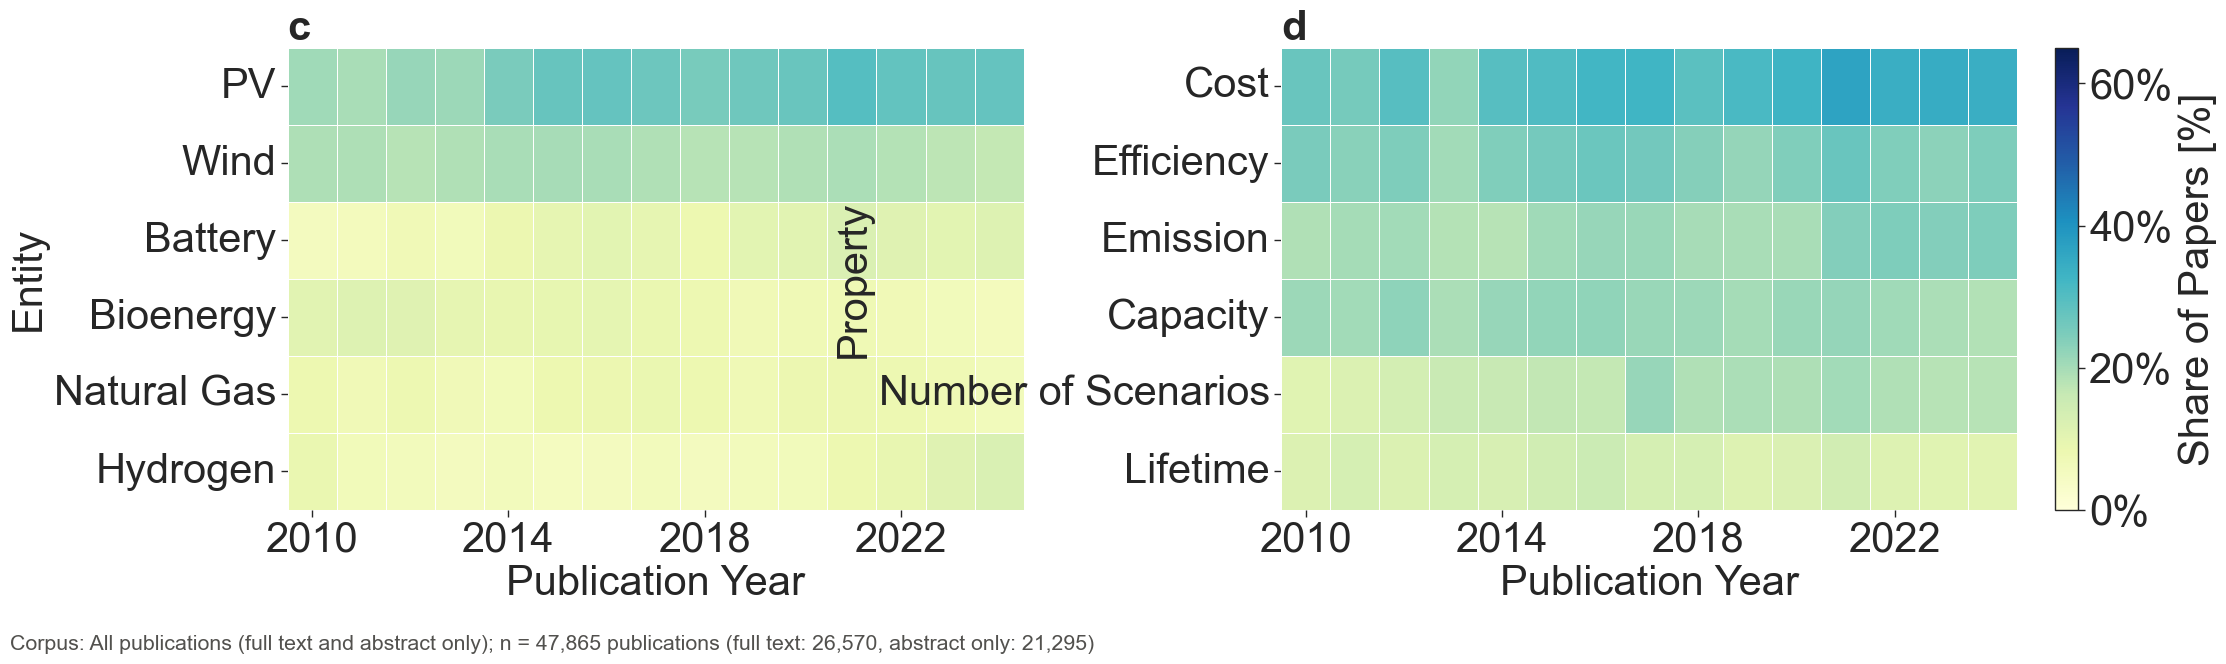

In [5]:
heatmap_df = quinex_df[quinex_df["publication_year"] < 2025]

fig, piv_entity, piv_property = metadata.mention_trend_heatmap(
    heatmap_df, 
    "entity_base_mapping", 
    "property_base_mapping", 
    figsize=(24,6), 
    font_size=30, 
    top_n=6, 
    cmap="YlGnBu",
    color_scale_percent=(0,65)
)
add_corpus_note(fig, describe_corpus(CORPUS, df=heatmap_df))
show_figure(fig)
# show_figure(fig, save_path=f"../data/figures/metadata/ent_prop_distribution_{CORPUS}.pdf")

### **Share of Publication per Country**

Country and SJR metadata (`metadata_df`) is only available for full-text publications, so this figure always uses the full-text corpus, independent of `CORPUS`.

Loading UN World Population Prospects data from ../data/visualisation_files/country_add_info/world_population.xlsx...
Loaded population data for 236 countries, years 1950-2100
Missing country info: 1542 papers (5.80%)
Missing SJR info: 1069 papers (4.02%)


c:\Gorres\Projekte\quinex_application\quinex_application\visualisation\metadata_visualisation.py:382: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ).fillna(0)
c:\Gorres\Projekte\quinex_application\quinex_application\visualisation\metadata_visualisation.py:443: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  agg[plot_column] = (agg['share_sum'] / agg['norm_share_sum']).fillna(0)


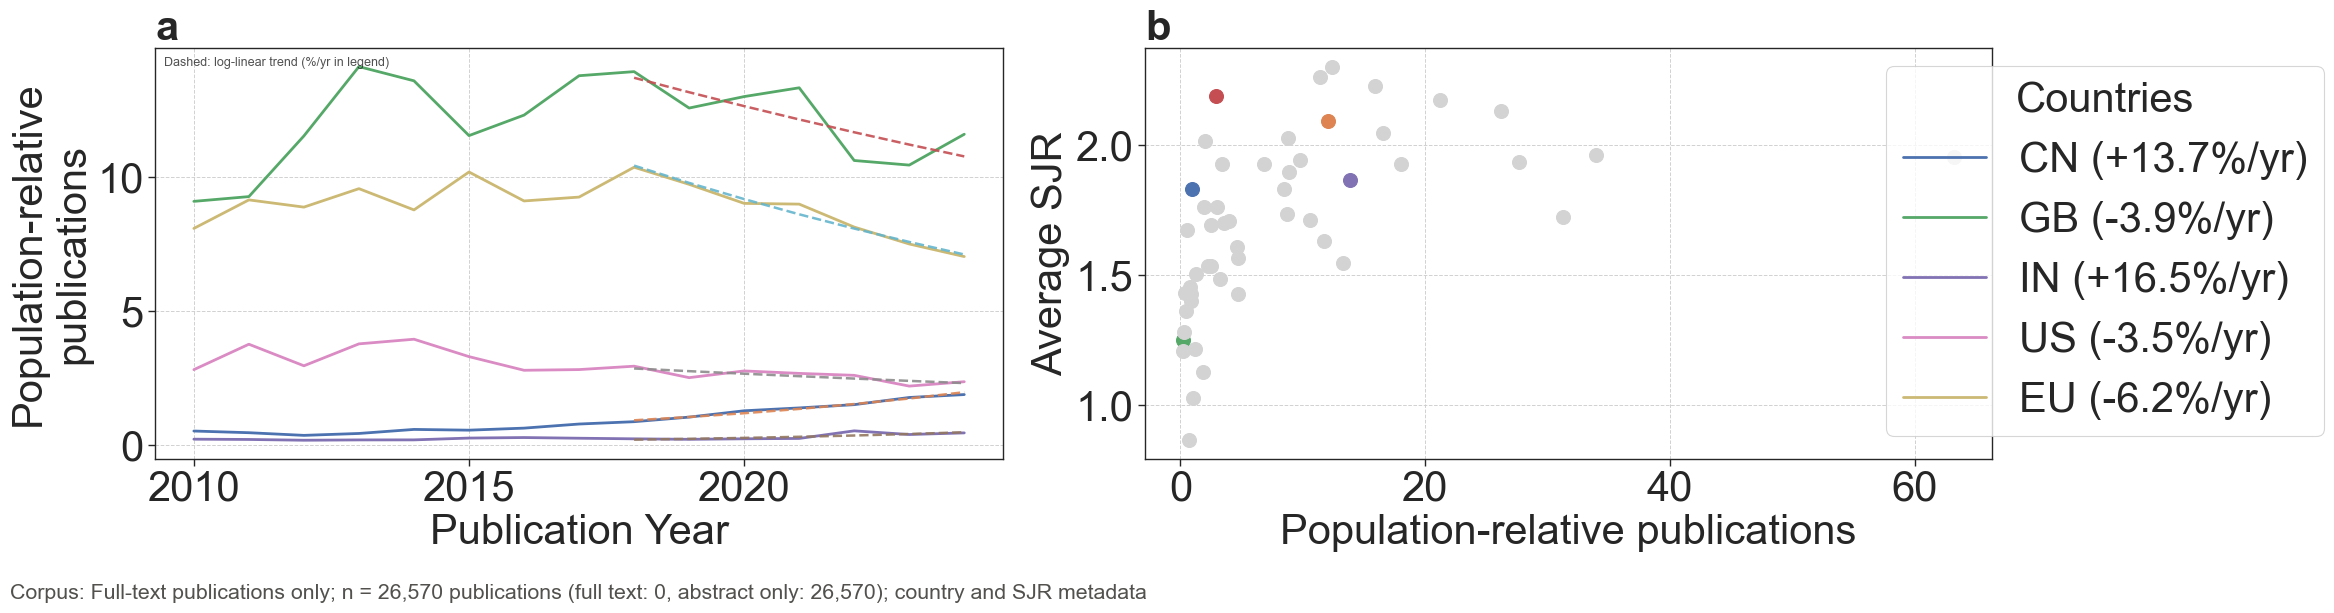

In [6]:
eu_countries = {
    "EU": ["DE", "FR", "IT", "ES", "NL", "BE", "AT", "SE", "DK", "PL", "GR", "PT", "CZ", "FI", "RO", "HU", "BG", "HR", "SI", "SK", "IE"]
}

fig, pivot_countries, avg_sjr = metadata.countries_share_and_sjr(
    metadata_df,
    top_n_line = 5, 
    top_n_scatter = 50, 
    figsize = (24, 6), 
    font_size=30, 
    legend_bbox=(0.885,0.55),
    max_year=2024,
    normalize_by_population=True,
    population_excel_path="../data/visualisation_files/country_add_info/world_population.xlsx",
    country_groups=eu_countries,
    add_regression_lines=True,
    regression_start_year=2018,
    regression_end_year=2024
)
add_corpus_note(fig, describe_corpus("full_text", df=metadata_df[metadata_df["publication_year"] <= 2024])
                + "; country and SJR metadata")
show_figure(fig)
# show_figure(fig, save_path="../data/figures/metadata/share_top_countries.pdf")

### **Entities and Properties per Country**

Countries are taken from `metadata_df`, so these heatmaps also cover full-text publications only, independent of `CORPUS`.

In [7]:
# Create DataFrames for additional top research nations
def get_df_by_country(metadata_df, quinex_df, country_code):
    """Filter quinex_df for publications from a specific country."""
    pubs = metadata_df[metadata_df['countries'].apply(lambda x: country_code in x)]
    dois = pubs['DOI'].tolist()
    return quinex_df[quinex_df['DOI'].isin(dois)]

# Create EU DataFrame by aggregating EU countries
def get_df_by_countries(metadata_df, quinex_df, country_codes):
    """Filter quinex_df for publications from a list of countries."""
    pubs = metadata_df[metadata_df['countries'].apply(
        lambda x: any(code in x for code in country_codes)
    )]
    dois = pubs['DOI'].tolist()
    return quinex_df[quinex_df['DOI'].isin(dois)]


df_ch = get_df_by_country(metadata_df[metadata_df["publication_year"] < 2025], quinex_df, "CN")  # China
df_us = get_df_by_country(metadata_df[metadata_df["publication_year"] < 2025], quinex_df, "US")  # United States
df_jp = get_df_by_country(metadata_df[metadata_df["publication_year"] < 2025], quinex_df, "JP")  # Japan
df_in = get_df_by_country(metadata_df[metadata_df["publication_year"] < 2025], quinex_df, "IN")  # India
df_gb = get_df_by_country(metadata_df[metadata_df["publication_year"] < 2025], quinex_df, "GB")  # United Kingdom

eu_codes = ["DE", "FR", "IT", "ES", "NL", "BE", "AT", "SE", "DK", "PL", "GR", "PT", "CZ", "FI", "RO", "HU", "BG", "HR", "SI", "SK", "IE"]
df_eu = get_df_by_countries(metadata_df[metadata_df["publication_year"] < 2025], quinex_df, eu_codes)

print(f"EU: {len(df_eu['DOI'].value_counts())} entries")
print(f"China: {len(df_ch['DOI'].value_counts())} entries")
print(f"USA: {len(df_us['DOI'].value_counts())} entries")
print(f"UK: {len(df_gb['DOI'].value_counts())} entries")
print(f"Japan: {len(df_jp['DOI'].value_counts())} entries")
print(f"India: {len(df_in['DOI'].value_counts())} entries")

EU: 9653 entries
China: 5591 entries
USA: 2895 entries
UK: 2596 entries
Japan: 625 entries
India: 1372 entries


c:\Gorres\Projekte\quinex_application\quinex_application\visualisation\metadata_visualisation.py:853: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.12, 1, 1])


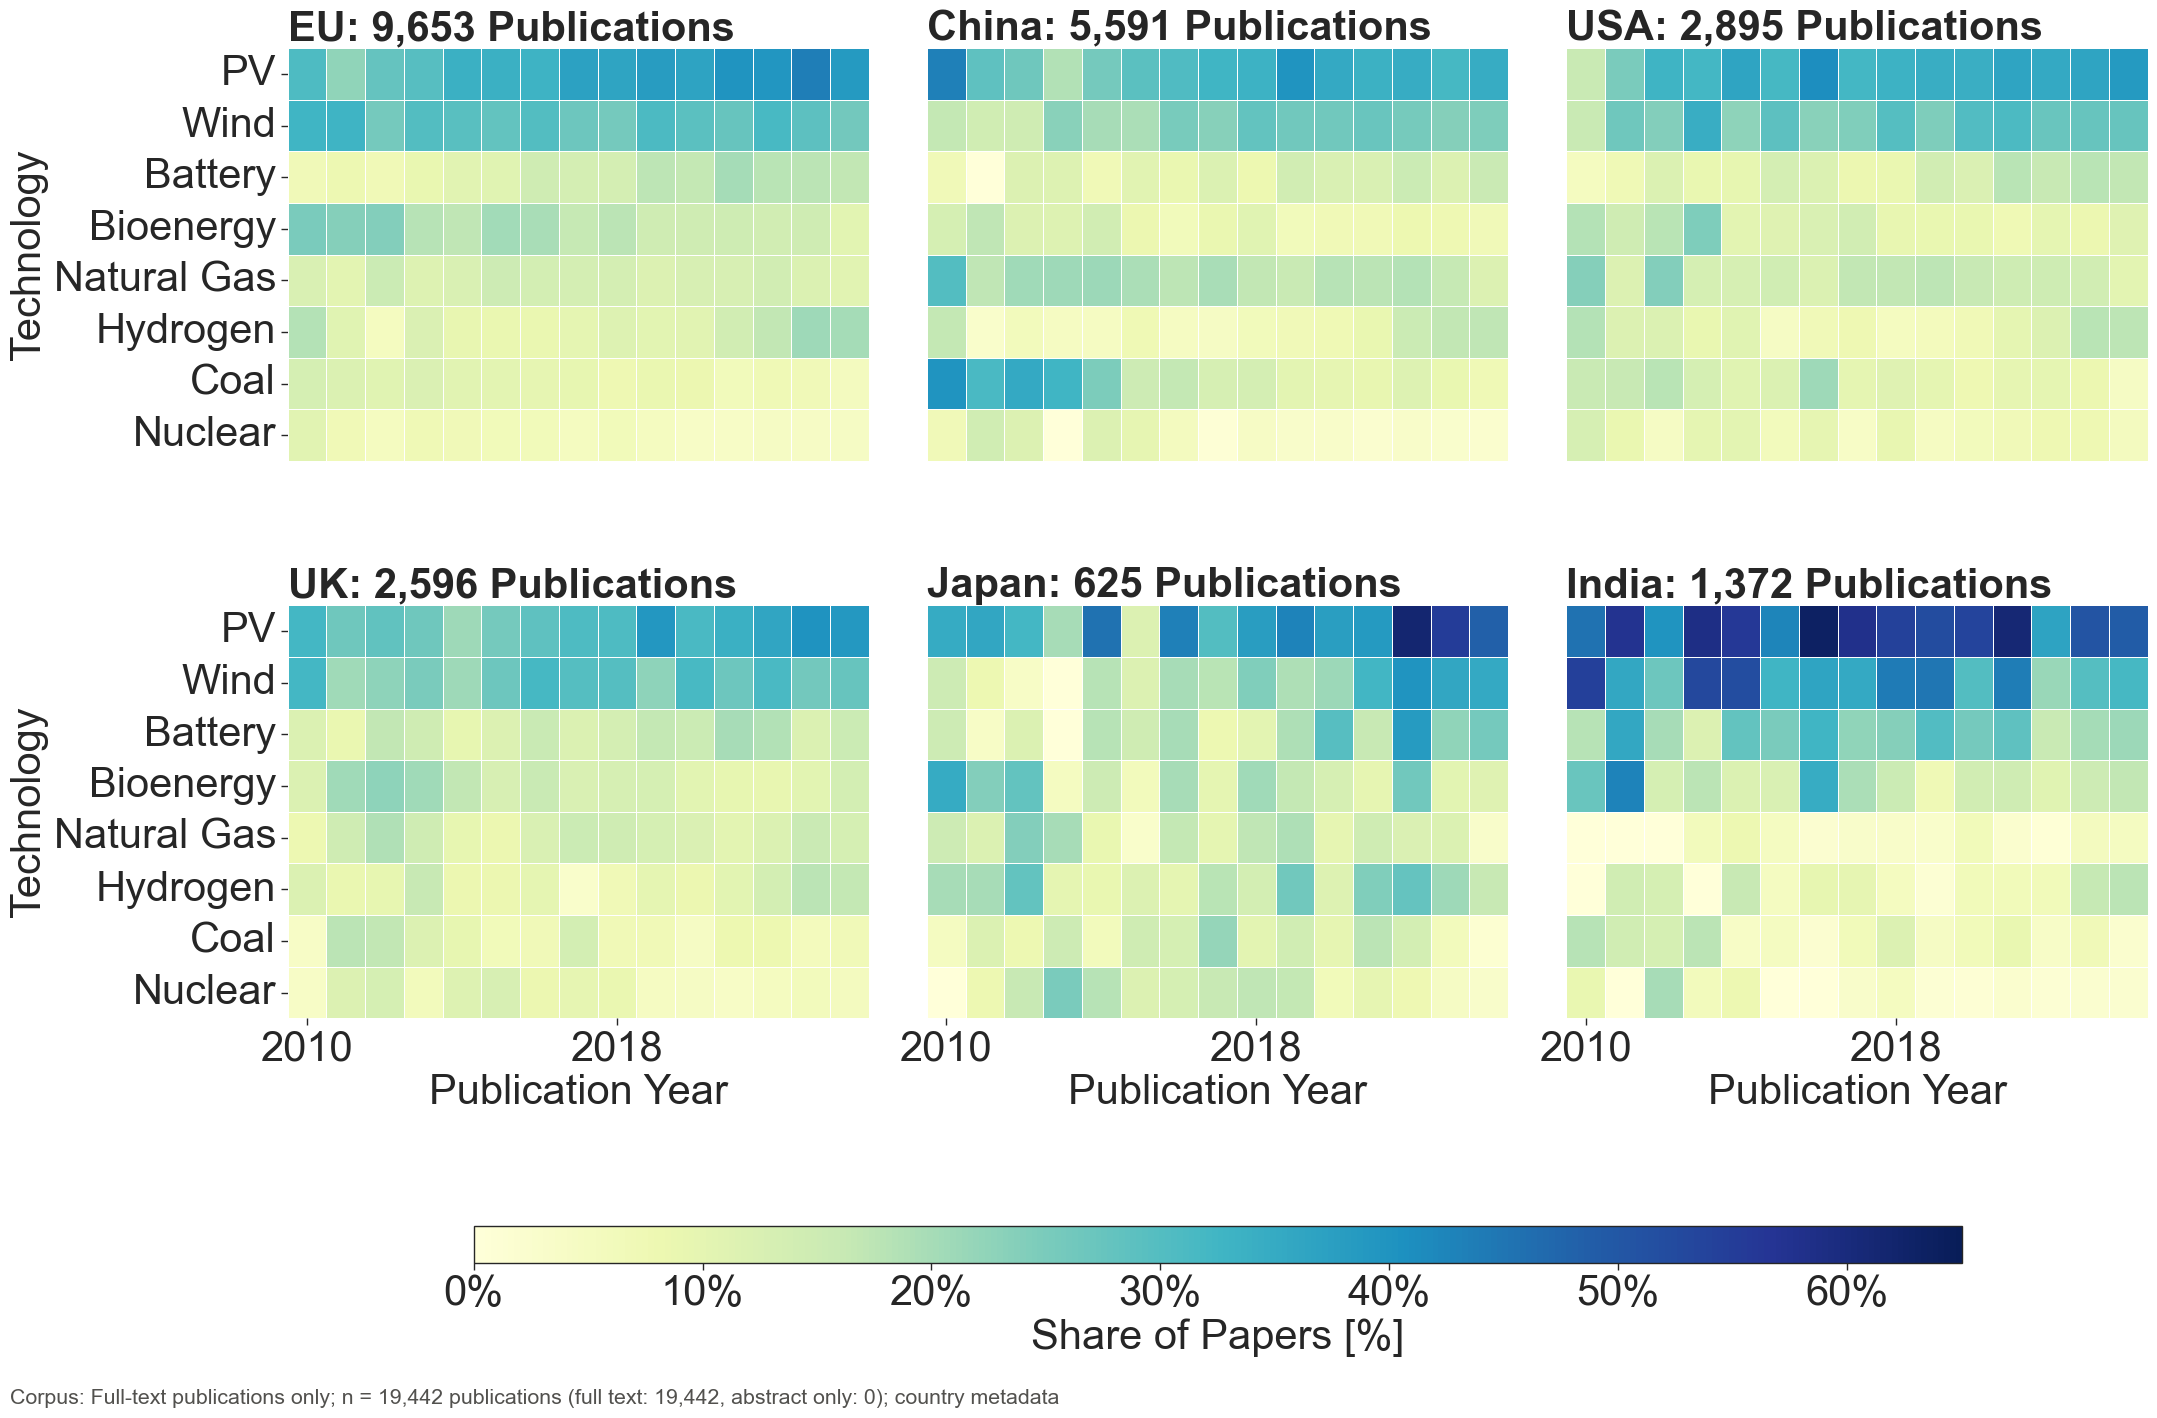

In [8]:
# 3 countries/regions: 3 columns, 1 row
country_dfs = [df_eu, df_ch, df_us, df_gb, df_jp, df_in]
country_names = ["EU", "China", "USA", "UK", "Japan", "India"]

fig, piv_entity = metadata.mention_trend_heatmap_multi_entities(
    dfs = country_dfs,
    titles = [f"{name}: {df['DOI'].nunique():,} Publications" for name, df in zip(country_names, country_dfs)],
    entity_col = "entity_base_mapping",
    figsize=(24, 9),
    font_size=30, 
    top_n=8, 
    cmap="YlGnBu",
    n_cols=3,
    color_scale_percent=(0,65)
)
add_corpus_note(fig, describe_corpus("full_text", df=pd.concat(country_dfs)) + "; country metadata")
show_figure(fig)
# show_figure(fig, save_path="../data/figures/metadata/ent_6countries.pdf")

# **Full Text vs. Abstract Only**

a) Mean extracted records per publication per year (dashed: mean over all years), b) share of full-text publications per year (dashed: share over all years), c) full text share per country with labelled examples.

Processed corpus: all publications with `Download_Status` "Succeeded" (full text) or "Abstract Succeeded" (abstract only), incl. publications without extracted records; independent of `CORPUS`. Label positions on the map can be adjusted with `label_positions={"GB": (lon, lat)}`.

Corpus: a, b: all processed publications 2010–2024 (incl. those without extracted records); n = 64,136 publications (full text: 26,570, abstract only: 37,566); Ø = mean over all years
c: publications with at least one extracted record and country information (whole counting); n = 27,600 publications (full text: 15,790, abstract only: 11,810); hatched: < 30 publications


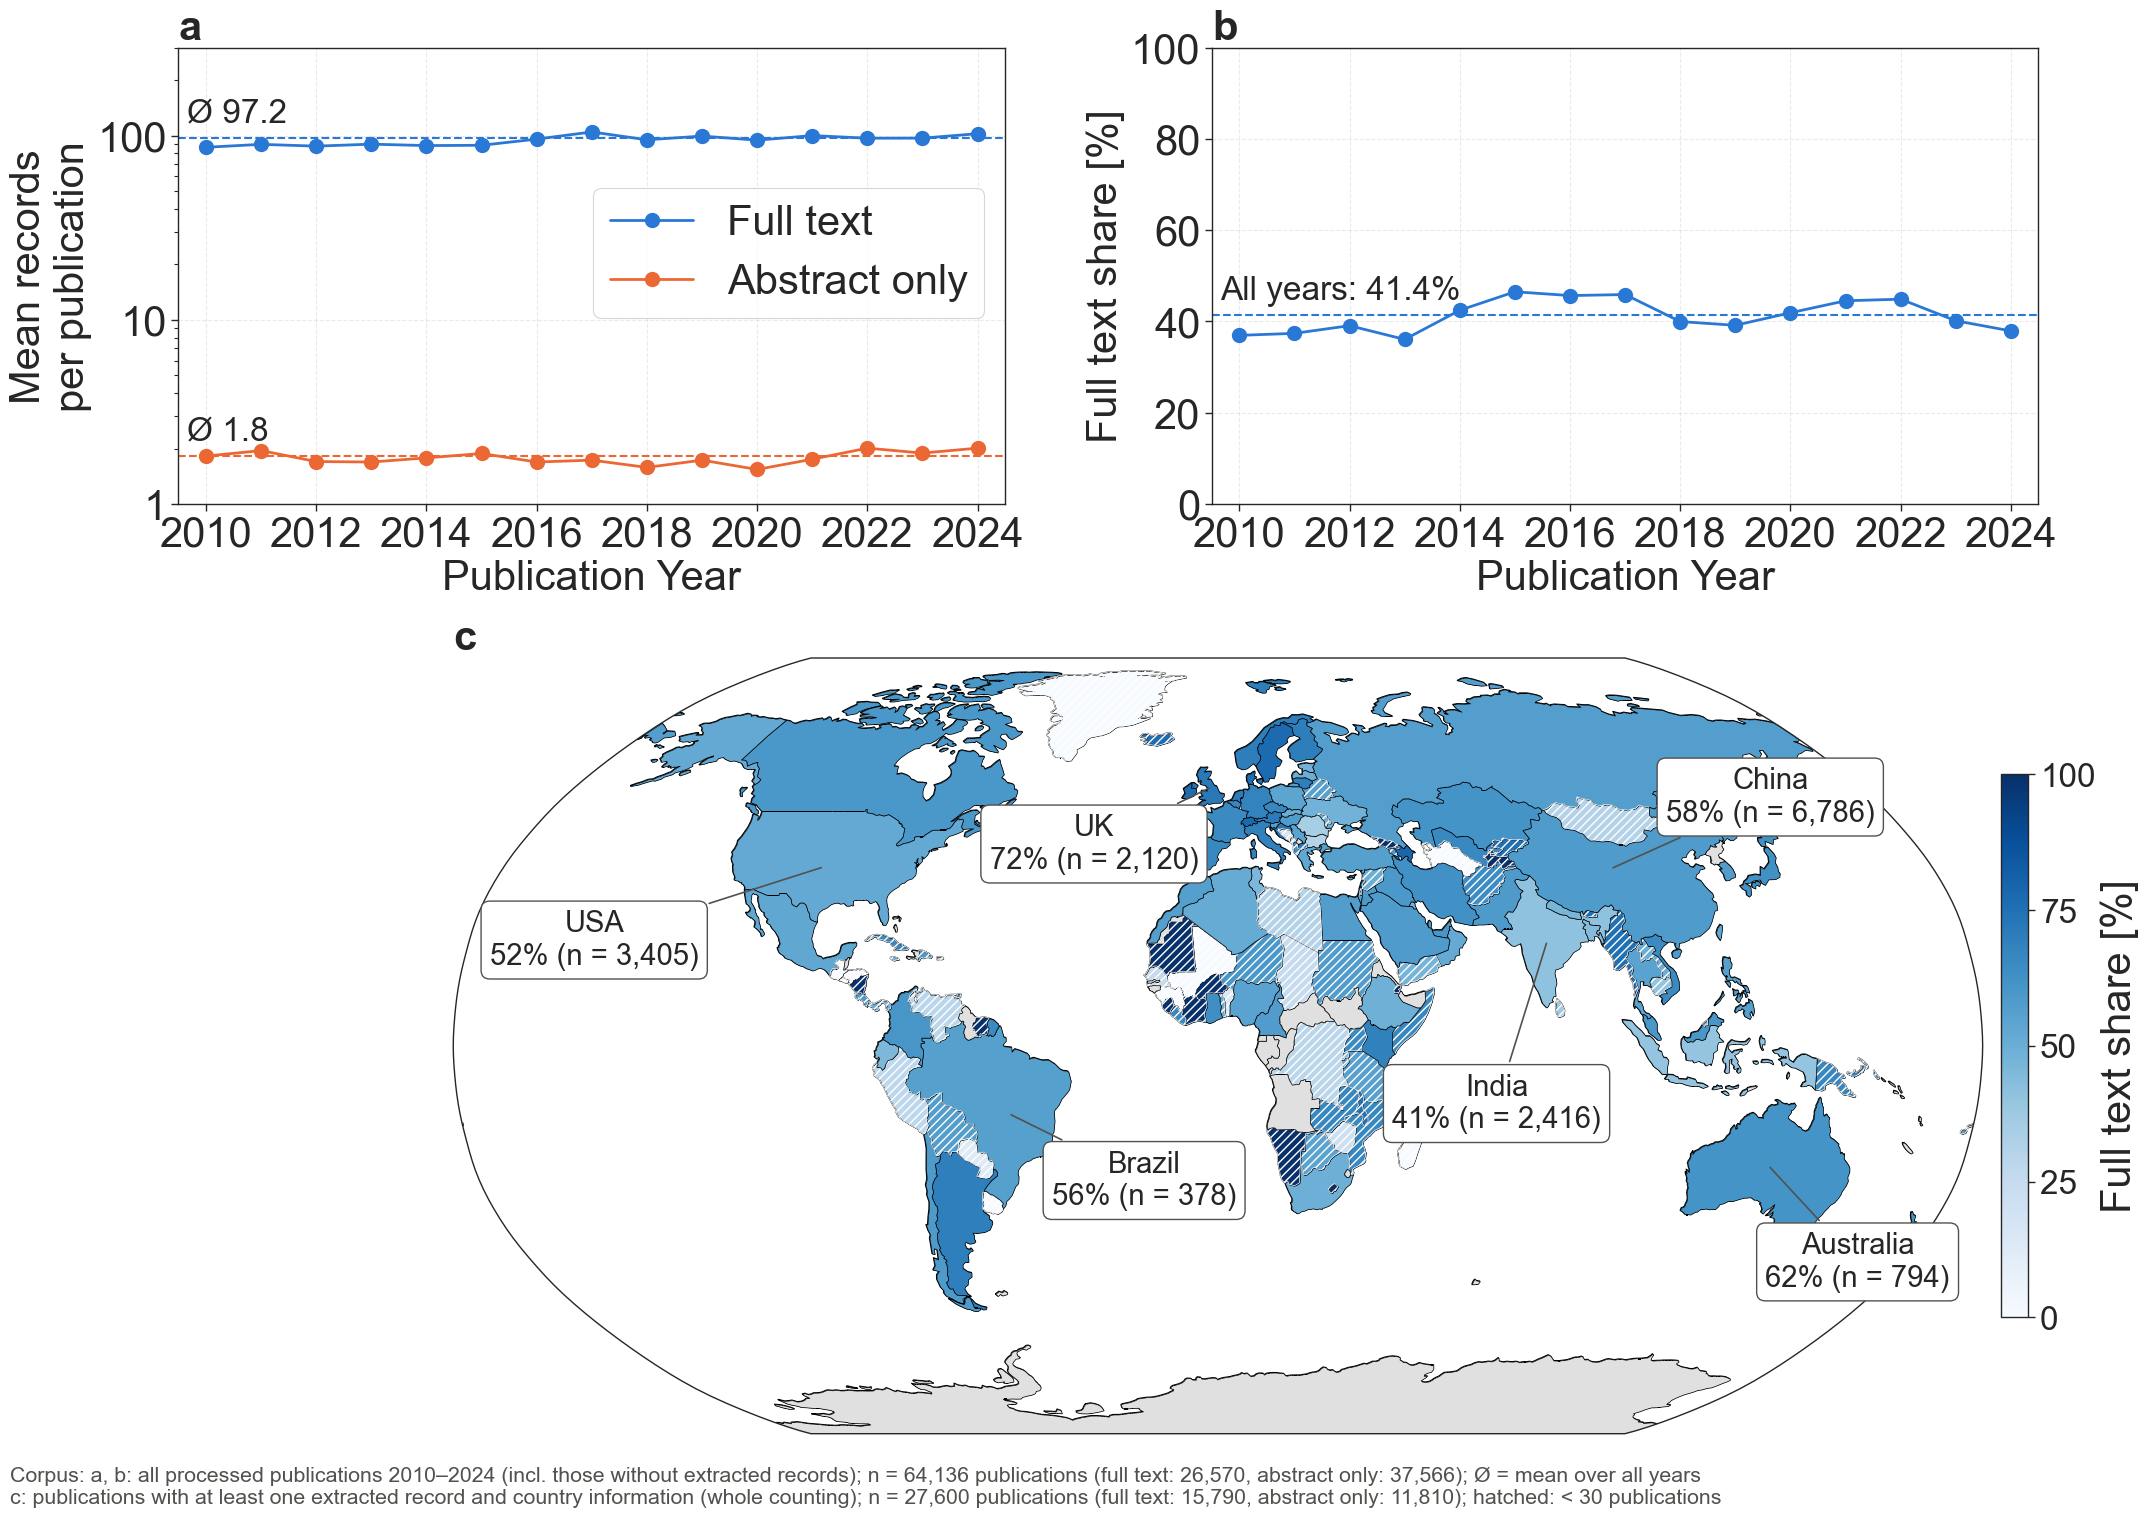

,publications,mean records / publication,full text share [%]
text_availability,,,
Full text,26570,97.22,41.43
Abstract only,37566,1.82,41.43


In [11]:
availability = TextAvailabilityVisualisation()
availability.add_text_availability(records_all)
pubs = availability.corpus_publication_table(df_paper, availability.publication_table(records_all))

fig, overview = availability.plot_text_availability_overview(
    pubs,
    year_range=(2010, 2024),
    example_countries=["US", "GB", "IN", "CN", "BR", "AU"],
    min_publications=30,
    figsize=(24, 18),
    font_size=30,
)
show_figure(fig, save_path="../data/figures/metadata/text_availability_overview.pdf")
overview["overall"]

In [10]:
# Full text share per country (whole counting), sorted by number of publications
country_shares = overview["countries"]
with pd.option_context("display.max_rows", None):
    print(country_shares.to_string())

# Single country, e.g.:
country_shares[country_shares["country name"] == "Algeria"]

                     country name  Full text  Abstract only  total  full text share [%]
country                                                                                
CN                          China       3964           2822   6786                58.41
US       United States of America       1770           1635   3405                51.98
IN                          India        994           1422   2416                41.14
GB                 United Kingdom       1530            590   2120                72.17
DE                        Germany       1417            660   2077                68.22
IT                          Italy       1000            452   1452                68.87
IR                           Iran        814            488   1302                62.52
CA                         Canada        619            415   1034                59.86
SA                   Saudi Arabia        570            406    976                58.40
DK                        Denmar

,country name,Full text,Abstract only,total,full text share [%]
country,,,,,
DZ,Algeria,148,141,289,51.21
